In [27]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [2]:
import numpy as np

train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

**Import thư viện từ src folder**

In [3]:
from src.preprocessing.scaler import scale_flat, prepare, scale_cnn, split_val
from src.models.logistic_regression import LogisticRegression
from src.evaluation.metrics import ClassificationMetrics
from src.models.ensemble_method_mlp import MLPEnsemble
from src.models.naive_bayes import GaussianNaiveBayes

In [4]:
X_train, X_val, y_train, y_val = split_val(X=X_train, y=y_train, val_size=0.1, seed=42)

In [5]:
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'X_val shape: {X_test.shape}')


X_train shape: (54000, 28, 28)
X_test shape: (10000, 28, 28)
X_val shape: (10000, 28, 28)


In [6]:
X_train_mlp, X_val_mlp, X_test_mlp, tools= scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode='raw')
X_train_logistic, X_val_logistic, X_test_logistic, tools=scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode='raw')

In [7]:
model = LogisticRegression(
    eta=0.1,
    lam= 0.001,
    max_epochs=100,
    batch_size=128,
    seed=42,
    tol=1e-7
)

In [10]:
%%time
model.fit(X_train_logistic, y_train)

CPU times: user 3min 26s, sys: 1.4 s, total: 3min 27s
Wall time: 23.6 s


In [11]:
y_pred_logistic = model.predict(X_test_logistic)

In [12]:
metrics = ClassificationMetrics(y_true=y_test, y_pred=y_pred_logistic)

In [13]:
metrics.report()

     Class  Precision     Recall         F1
         0      0.943      0.980      0.961 
         1      0.953      0.978      0.965 
         2      0.932      0.890      0.910 
         3      0.902      0.907      0.905 
         4      0.930      0.924      0.927 
         5      0.910      0.857      0.882 
         6      0.924      0.950      0.937 
         7      0.918      0.918      0.918 
         8      0.882      0.878      0.880 
         9      0.892      0.902      0.897 
 Macro avg      0.919      0.918      0.918 

Accuracy: 0.919


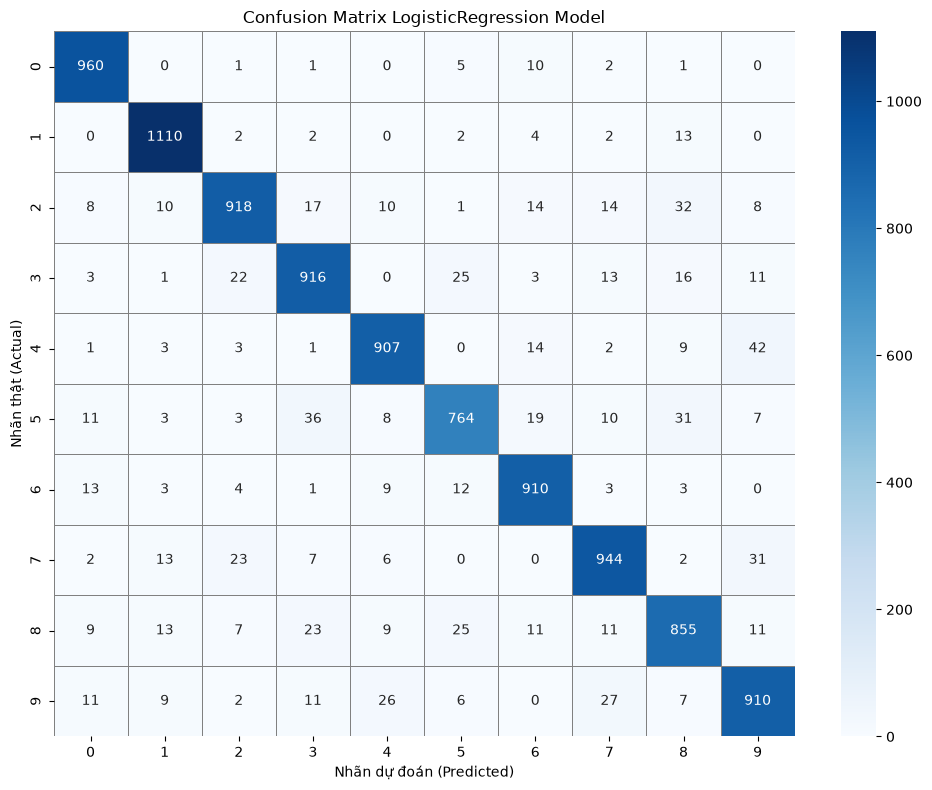

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

cm, labels = metrics.get_confustion_matrix()

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, 
    fmt="d",          
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
)

plt.xlabel("Nhãn dự đoán (Predicted)")
plt.ylabel("Nhãn thật (Actual)")
plt.title("Confusion Matrix LogisticRegression Model")
plt.tight_layout()
plt.show()

In [15]:
from src.models.mlp import MLP

In [16]:
model_mlp = MLP(
    sizes=(784, 500, 10),
    activation='relu',
    p_drop=0.2,
    init='he',
    seed=42,
    )

In [17]:
%%time
model_mlp.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=20,
    batch_size=128,
    lr=0.08,
)

Epoch 01/20 | train loss 0.1220 acc 0.9627 | val loss 0.1467 acc 0.9560
Epoch 02/20 | train loss 0.0717 acc 0.9790 | val loss 0.1079 acc 0.9697
Epoch 03/20 | train loss 0.0487 acc 0.9864 | val loss 0.0883 acc 0.9750
Epoch 04/20 | train loss 0.0424 acc 0.9876 | val loss 0.0868 acc 0.9772
Epoch 05/20 | train loss 0.0301 acc 0.9916 | val loss 0.0781 acc 0.9770
Epoch 06/20 | train loss 0.0243 acc 0.9936 | val loss 0.0758 acc 0.9793
Epoch 07/20 | train loss 0.0182 acc 0.9957 | val loss 0.0724 acc 0.9810
Epoch 08/20 | train loss 0.0154 acc 0.9962 | val loss 0.0726 acc 0.9790
Epoch 09/20 | train loss 0.0124 acc 0.9973 | val loss 0.0700 acc 0.9810
Epoch 10/20 | train loss 0.0113 acc 0.9976 | val loss 0.0761 acc 0.9793
Epoch 11/20 | train loss 0.0087 acc 0.9983 | val loss 0.0715 acc 0.9808
Epoch 12/20 | train loss 0.0069 acc 0.9990 | val loss 0.0687 acc 0.9810
Epoch 13/20 | train loss 0.0054 acc 0.9993 | val loss 0.0671 acc 0.9825
Epoch 14/20 | train loss 0.0052 acc 0.9991 | val loss 0.0677 acc

{'train_loss': [0.12197222546846778,
  0.0716630471525369,
  0.048713177994445515,
  0.04235052269090105,
  0.030118336142213258,
  0.02426413512202325,
  0.018197110146973974,
  0.015359702899500175,
  0.012427320462410097,
  0.011264218000212201,
  0.0086736596810321,
  0.00685372684771816,
  0.005417362027974041,
  0.005227180094354683,
  0.004290506467913036,
  0.004301858143191095,
  0.0036497071937278466,
  0.0029449083074858345,
  0.0020604383855782173,
  0.0021104476569841304],
 'train_acc': [0.9626851851851852,
  0.979037037037037,
  0.9863518518518518,
  0.9876296296296296,
  0.9916111111111111,
  0.9935555555555555,
  0.9957407407407407,
  0.9962407407407408,
  0.9972962962962963,
  0.9975925925925926,
  0.9982962962962963,
  0.9989629629629629,
  0.9992592592592593,
  0.9991481481481481,
  0.9995925925925926,
  0.9995185185185185,
  0.9996111111111111,
  0.9997407407407407,
  0.9999629629629629,
  0.9999444444444444],
 'val_loss': [0.1466781049966812,
  0.10792066653569539,

In [18]:
y_pred_mlp = model_mlp.predict(X_test_mlp)
metrics_mlp = ClassificationMetrics(y_true=y_test, y_pred=y_pred_mlp)
metrics_mlp.report()

     Class  Precision     Recall         F1
         0      0.985      0.992      0.988 
         1      0.993      0.993      0.993 
         2      0.984      0.983      0.983 
         3      0.976      0.983      0.980 
         4      0.987      0.984      0.985 
         5      0.990      0.979      0.984 
         6      0.986      0.984      0.985 
         7      0.981      0.983      0.982 
         8      0.972      0.982      0.977 
         9      0.982      0.971      0.977 
 Macro avg      0.983      0.983      0.983 

Accuracy: 0.984


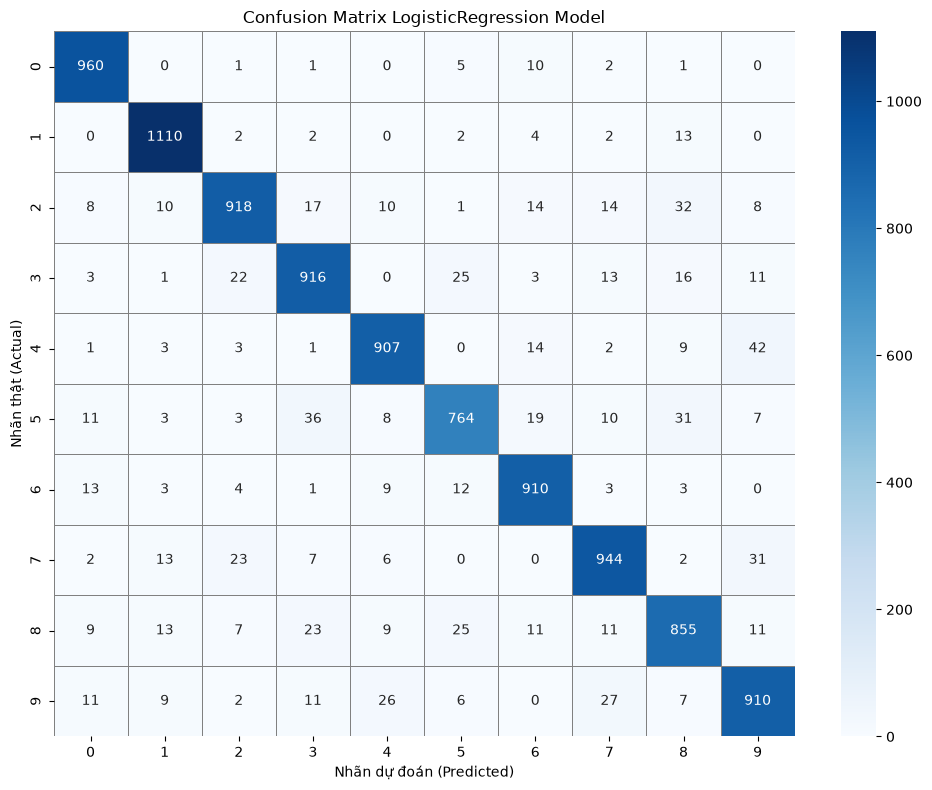

In [19]:
cn, labels = metrics_mlp.get_confustion_matrix()

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, 
    fmt="d",          
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
)

plt.xlabel("Nhãn dự đoán (Predicted)")
plt.ylabel("Nhãn thật (Actual)")
plt.title("Confusion Matrix LogisticRegression Model")
plt.tight_layout()
plt.show()

In [20]:
model_ensemble_mlp = MLPEnsemble(
    sizes=(784, 500, 10),
    seeds=(42, 123, 2026),
    p_drop=0.3,
    init="he",
)

In [22]:
model_ensemble_mlp.fit(
    X=X_train_mlp,
    y=y_train,
    validation_data=(X_val_mlp,y_val),
    patience=5,
    momentum=0.9,
    epochs=20,
    lr=0.05
)


Training member 1/3 (seed=42)
Epoch 01/20 | train loss 0.1462 acc 0.9565 | val loss 0.1710 acc 0.9527
Epoch 02/20 | train loss 0.0919 acc 0.9737 | val loss 0.1196 acc 0.9647
Epoch 03/20 | train loss 0.0690 acc 0.9803 | val loss 0.1012 acc 0.9688
Epoch 04/20 | train loss 0.0563 acc 0.9841 | val loss 0.0914 acc 0.9742
Epoch 05/20 | train loss 0.0422 acc 0.9886 | val loss 0.0826 acc 0.9763
Epoch 06/20 | train loss 0.0340 acc 0.9909 | val loss 0.0755 acc 0.9792
Epoch 07/20 | train loss 0.0302 acc 0.9923 | val loss 0.0745 acc 0.9778
Epoch 08/20 | train loss 0.0245 acc 0.9939 | val loss 0.0698 acc 0.9810
Epoch 09/20 | train loss 0.0221 acc 0.9942 | val loss 0.0705 acc 0.9802
Epoch 10/20 | train loss 0.0179 acc 0.9959 | val loss 0.0691 acc 0.9810
Epoch 11/20 | train loss 0.0161 acc 0.9965 | val loss 0.0715 acc 0.9795
Epoch 12/20 | train loss 0.0125 acc 0.9976 | val loss 0.0665 acc 0.9820
Epoch 13/20 | train loss 0.0122 acc 0.9975 | val loss 0.0685 acc 0.9808
Epoch 14/20 | train loss 0.0107 a

In [23]:
y_pred = model_ensemble_mlp.predict(X=X_test_mlp)

In [24]:
metrics_ensemble = ClassificationMetrics(y_true=y_test, y_pred=y_pred)

In [25]:
metrics_ensemble.report()

     Class  Precision     Recall         F1
         0      0.985      0.991      0.988 
         1      0.992      0.993      0.993 
         2      0.984      0.984      0.984 
         3      0.981      0.983      0.982 
         4      0.983      0.985      0.984 
         5      0.989      0.982      0.985 
         6      0.984      0.984      0.984 
         7      0.982      0.982      0.982 
         8      0.983      0.977      0.980 
         9      0.979      0.981      0.980 
 Macro avg      0.984      0.984      0.984 

Accuracy: 0.984


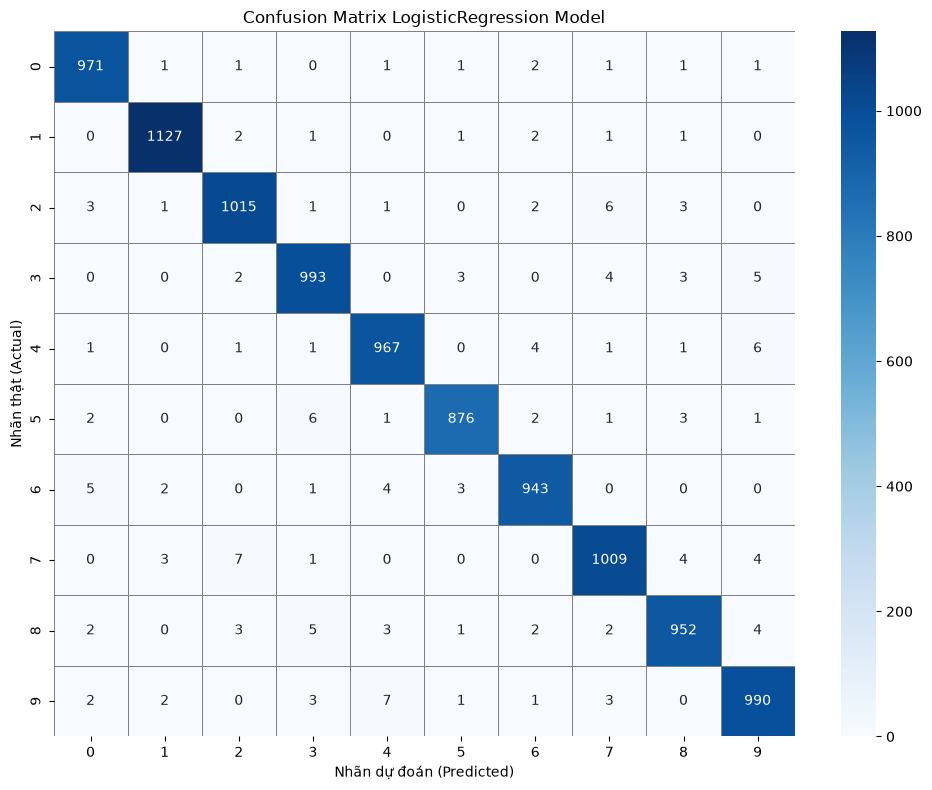

In [26]:
cm, labels = metrics_ensemble.get_confustion_matrix()

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, 
    fmt="d",          
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
)

plt.xlabel("Nhãn dự đoán (Predicted)")
plt.ylabel("Nhãn thật (Actual)")
plt.title("Confusion Matrix LogisticRegression Model")
plt.tight_layout()
plt.show()

In [ ]:
from src.models.mlp import MLP

In [ ]:
model_mlp = MLP(
    sizes=(784, 500, 10),
    activation='relu',
    p_drop=0.2,
    init='he',
    seed=42,
    )

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(48000, 784), dtype=uint8)

In [ ]:
%%time
model_mlp.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=20,
    batch_size=128,
    lr=0.08,
)

Epoch 01/20 | train loss 0.1220 acc 0.9627 | val loss 0.1467 acc 0.9560
Epoch 02/20 | train loss 0.0717 acc 0.9790 | val loss 0.1079 acc 0.9697
Epoch 03/20 | train loss 0.0487 acc 0.9864 | val loss 0.0883 acc 0.9750
Epoch 04/20 | train loss 0.0424 acc 0.9876 | val loss 0.0868 acc 0.9772
Epoch 05/20 | train loss 0.0301 acc 0.9916 | val loss 0.0781 acc 0.9770
Epoch 06/20 | train loss 0.0243 acc 0.9936 | val loss 0.0758 acc 0.9793
Epoch 07/20 | train loss 0.0182 acc 0.9957 | val loss 0.0724 acc 0.9810
Epoch 08/20 | train loss 0.0154 acc 0.9962 | val loss 0.0726 acc 0.9790
Epoch 09/20 | train loss 0.0124 acc 0.9973 | val loss 0.0700 acc 0.9810
Epoch 10/20 | train loss 0.0113 acc 0.9976 | val loss 0.0761 acc 0.9793
Epoch 11/20 | train loss 0.0087 acc 0.9983 | val loss 0.0715 acc 0.9808
Epoch 12/20 | train loss 0.0069 acc 0.9990 | val loss 0.0687 acc 0.9810
Epoch 13/20 | train loss 0.0054 acc 0.9993 | val loss 0.0671 acc 0.9825
Epoch 14/20 | train loss 0.0052 acc 0.9991 | val loss 0.0677 acc

{'train_loss': [0.12197222546846778,
  0.0716630471525369,
  0.048713177994445515,
  0.04235052269090105,
  0.030118336142213258,
  0.02426413512202325,
  0.018197110146973974,
  0.015359702899500175,
  0.012427320462410097,
  0.011264218000212201,
  0.0086736596810321,
  0.00685372684771816,
  0.005417362027974041,
  0.005227180094354683,
  0.004290506467913036,
  0.004301858143191095,
  0.0036497071937278466,
  0.0029449083074858345,
  0.0020604383855782173,
  0.0021104476569841304],
 'train_acc': [0.9626851851851852,
  0.979037037037037,
  0.9863518518518518,
  0.9876296296296296,
  0.9916111111111111,
  0.9935555555555555,
  0.9957407407407407,
  0.9962407407407408,
  0.9972962962962963,
  0.9975925925925926,
  0.9982962962962963,
  0.9989629629629629,
  0.9992592592592593,
  0.9991481481481481,
  0.9995925925925926,
  0.9995185185185185,
  0.9996111111111111,
  0.9997407407407407,
  0.9999629629629629,
  0.9999444444444444],
 'val_loss': [0.1466781049966812,
  0.10792066653569539,

In [ ]:
y_pred = model_mlp.predict(X_test_mlp)
metrics_mlp = ClassificationMetrics(y_true=y_test, y_pred=y_pred)
metrics_mlp.report()

     Class  Precision     Recall         F1
         0      0.985      0.992      0.988 
         1      0.993      0.993      0.993 
         2      0.984      0.983      0.983 
         3      0.976      0.983      0.980 
         4      0.987      0.984      0.985 
         5      0.990      0.979      0.984 
         6      0.986      0.984      0.985 
         7      0.981      0.983      0.982 
         8      0.972      0.982      0.977 
         9      0.982      0.971      0.977 
 Macro avg      0.983      0.983      0.983 

Accuracy: 0.984


In [ ]:
"""Example: load MNIST OUTSIDE the model and fit() functions."""

import torch
from torch.utils.data import random_split, DataLoader
from torchvision import datasets, transforms

from src.models.cnn import CNN, fit, evaluate

torch.manual_seed(42)

# 1. Load original dataset
mnist_train = datasets.MNIST(
    root='./data', train=True, download=True,
    transform=transforms.ToTensor()
)

mnist_test = datasets.MNIST(
    root='./data', train=False, download=True,
    transform=transforms.ToTensor()
)

# 2. Split train and validation
train_data, val_data = random_split(mnist_train, [54000, 6000])

# 3. Initialize and train model
model = CNN(dropout=0.2)

model = fit(
    model,
    train_data,
    val_data,
    epochs=6,
    batch_size=64,
    lr=0.001,
    patience=4
)

# 4. Evaluate on test dataset
test_loss, test_acc = evaluate(model, mnist_test)

print(f'Test loss={test_loss:.4f} | Test accuracy={test_acc:.2%}')

Epoch 1/6 | train loss=0.3588 | train acc=88.67% | val loss=0.1088 | val acc=96.80%
Epoch 2/6 | train loss=0.1110 | train acc=96.64% | val loss=0.0733 | val acc=97.92%
Epoch 3/6 | train loss=0.0805 | train acc=97.52% | val loss=0.0644 | val acc=98.13%
Epoch 4/6 | train loss=0.0652 | train acc=98.04% | val loss=0.0660 | val acc=98.20%
Epoch 5/6 | train loss=0.0549 | train acc=98.31% | val loss=0.0518 | val acc=98.58%
Epoch 6/6 | train loss=0.0455 | train acc=98.66% | val loss=0.0475 | val acc=98.67%
Test loss=0.0345 | Test accuracy=98.95%

Prediction results:
Predictions: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
True labels: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]

Prediction accuracy: 98.95%


In [ ]:
image, label = mnist_test[3]

# Dự đoán
pred = model.predict(image)
probs = model.predict_proba(image)

# Hiển thị kết quả
print("True label:", label)
print("Predicted label:", pred.item())
print("Confidence:", f"{probs.max().item():.2%}")

True label: 0
Predicted label: 0
Confidence: 100.00%


In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
image = train_data["X"][1]
label = train_data["y"][1]

In [ ]:
model.predict(image), label

(tensor([0]), np.int64(0))